# Model Monitoring Platform — Results Analysis

This notebook analyses the six-month simulated model deployment.

It evaluates model performance, feature drift, fairness and alert detection using the regenerated monitoring results.


## 1. Load libraries and project data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ast
from pathlib import Path

DATA = Path("../data")
REPORTS = Path("../reports")

metrics = pd.read_csv(REPORTS / "monthly_metrics.csv")
detection = pd.read_csv(REPORTS / "detection_analysis.csv")
drift = pd.read_csv(REPORTS / "drift_by_feature.csv")

display(metrics)


,month,evaluation_type,n_rows,accuracy,precision,recall,f1,fairness_tpr,fairness_gap,evidently_drift_share,...,alerts,roc_auc,fpr_gap,selection_rate_gap,outcome_rate_gap,n_female,n_male,n_positive_female,n_positive_male,drifted_features
0,1,held_out_baseline,300,0.6967,0.7174,0.7719,0.7437,"{'F': 0.7441860465116279, 'M': 0.8}",0.0558,NaN,...,[],0.7206,0.0766,0.0255,0.0677,142,158,86,85,NaN
1,2,monthly_production,1200,0.7033,0.7262,0.7980,0.7604,"{'F': 0.8088642659279779, 'M': 0.7867435158501...",0.0221,0.2,...,[],0.7646,0.0038,0.0200,0.0233,600,600,361,347,credit_history
2,3,monthly_production,1200,0.7075,0.7394,0.7700,0.7544,"{'F': 0.7741935483870968, 'M': 0.766016713091922}",0.0082,0.6,...,['WARNING: Evidently dataset drift (>=50% of f...,0.7649,0.0019,0.0006,0.0086,589,611,341,359,"income,debt_ratio,credit_history"
3,4,monthly_production,1200,0.7292,0.7503,0.7968,0.7729,"{'F': 0.7970588235294118, 'M': 0.7966101694915...",0.0004,0.8,...,['WARNING: Evidently dataset drift (>=50% of f...,0.7900,0.0151,0.0090,0.0056,585,615,340,354,"age,income,debt_ratio,credit_history"
4,5,monthly_production,1200,0.6917,0.6658,0.8019,0.7275,"{'F': 0.8392857142857143, 'M': 0.7708333333333...",0.0685,0.8,...,"['CRITICAL: accuracy below 0.70', 'WARNING: ou...",0.7724,0.0371,0.0195,0.0882,597,603,280,336,"age,income,debt_ratio,credit_history"
5,6,monthly_production,1200,0.6650,0.6150,0.8014,0.6959,"{'F': 0.8808510638297873, 'M': 0.7463126843657...",0.1345,0.8,...,"['CRITICAL: accuracy below 0.70', 'WARNING: fa...",0.7418,0.0962,0.0566,0.1606,592,608,235,339,"age,income,debt_ratio,credit_history"


## 2. Dataset overview

In [2]:
dataset = pd.read_csv(DATA / "six_months.csv")

print("Total records:", len(dataset))
print("Number of months:", dataset["month"].nunique())
print("\nRecords per month:")
display(dataset.groupby("month").size().rename("records").to_frame())

print("\nApproval rate by month:")
display(dataset.groupby("month")["approved"].mean().round(4))


Total records: 7200
Number of months: 6

Records per month:


,records
month,
1,1200
2,1200
3,1200
4,1200
5,1200
6,1200



Approval rate by month:


month
1    0.5692
2    0.5900
3    0.5833
4    0.5783
5    0.5133
6    0.4783
Name: approved, dtype: float64

## 3. Model performance across six months

,month,accuracy,precision,recall,f1,roc_auc
0,1,0.6967,0.7174,0.7719,0.7437,0.7206
1,2,0.7033,0.7262,0.7980,0.7604,0.7646
2,3,0.7075,0.7394,0.7700,0.7544,0.7649
3,4,0.7292,0.7503,0.7968,0.7729,0.7900
4,5,0.6917,0.6658,0.8019,0.7275,0.7724
5,6,0.6650,0.6150,0.8014,0.6959,0.7418


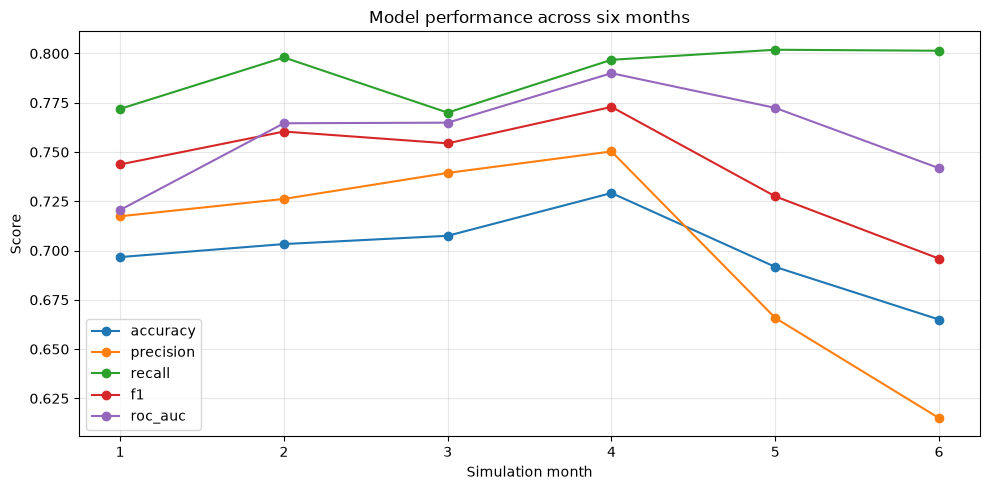

In [3]:
performance_columns = ["accuracy", "precision", "recall", "f1", "roc_auc"]

display(metrics[["month"] + performance_columns].round(4))

ax = metrics.plot(
    x="month",
    y=performance_columns,
    marker="o",
    figsize=(10, 5)
)
ax.set_title("Model performance across six months")
ax.set_xlabel("Simulation month")
ax.set_ylabel("Score")
ax.set_xticks(metrics["month"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Feature drift analysis

,month,evidently_drift_share,drift_detected
0,1,NaN,NaN
1,2,0.2,False
2,3,0.6,True
3,4,0.8,True
4,5,0.8,True
5,6,0.8,True


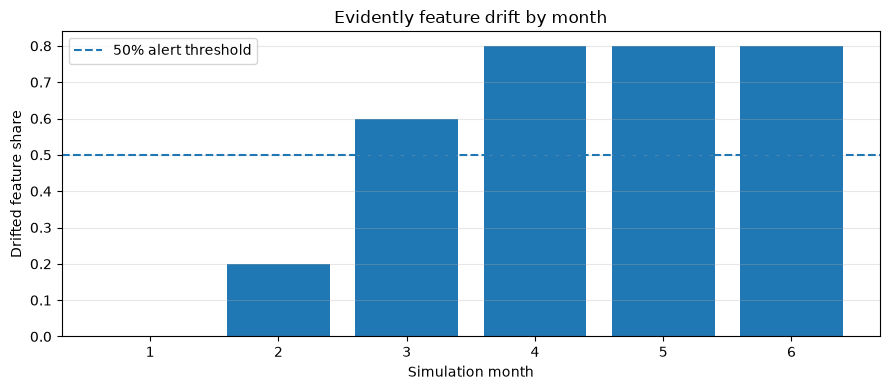

,month,feature,method,threshold,score,drifted
0,2,age,K-S p_value,0.05,4.528439e-01,False
1,2,income,K-S p_value,0.05,6.841702e-01,False
2,2,debt_ratio,K-S p_value,0.05,2.695955e-01,False
3,2,credit_history,K-S p_value,0.05,2.935752e-02,True
4,2,region,jensenshannon,0.10,4.449374e-02,False
5,3,age,K-S p_value,0.05,2.695955e-01,False
6,3,income,K-S p_value,0.05,7.639501e-04,True
7,3,debt_ratio,K-S p_value,0.05,2.522569e-02,True
8,3,credit_history,K-S p_value,0.05,3.275169e-06,True
9,3,region,jensenshannon,0.10,3.807831e-02,False


In [4]:
drift_summary = metrics[["month", "evidently_drift_share", "drift_detected"]]
display(drift_summary)

plt.figure(figsize=(9, 4))
plt.bar(
    metrics["month"].astype(str),
    metrics["evidently_drift_share"].fillna(0)
)
plt.axhline(0.5, linestyle="--", label="50% alert threshold")
plt.xlabel("Simulation month")
plt.ylabel("Drifted feature share")
plt.title("Evidently feature drift by month")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(drift)


## 5. Fairness analysis

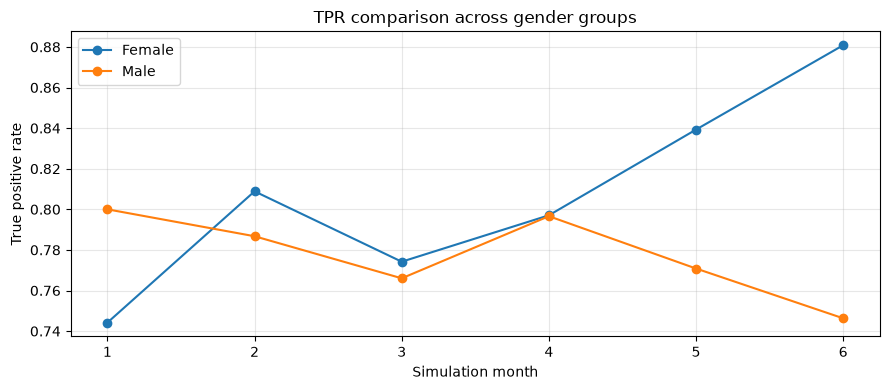

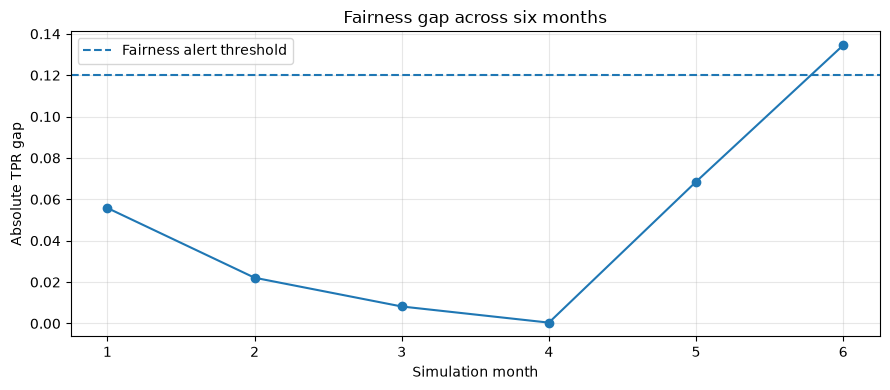

In [5]:
metrics["tpr_female"] = metrics["fairness_tpr"].apply(
    lambda x: ast.literal_eval(x)["F"]
)
metrics["tpr_male"] = metrics["fairness_tpr"].apply(
    lambda x: ast.literal_eval(x)["M"]
)

plt.figure(figsize=(9, 4))
plt.plot(metrics["month"], metrics["tpr_female"], marker="o", label="Female")
plt.plot(metrics["month"], metrics["tpr_male"], marker="o", label="Male")
plt.xlabel("Simulation month")
plt.ylabel("True positive rate")
plt.title("TPR comparison across gender groups")
plt.xticks(metrics["month"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(metrics["month"], metrics["fairness_gap"], marker="o")
plt.axhline(0.12, linestyle="--", label="Fairness alert threshold")
plt.xlabel("Simulation month")
plt.ylabel("Absolute TPR gap")
plt.title("Fairness gap across six months")
plt.xticks(metrics["month"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Alert detection and time to detection

,signal,planted_month,first_alert_month,delay_batches,false_positive_months
0,"Original rule: ANY feature drifted, Evidently ...",3,3,0,2
1,"Final: dataset drift (>=50% features, JS for r...",3,3,0,none
2,Accuracy < 0.70,4,5,1,none
3,"Accuracy < 0.70, statistically confirmed (95% ...",4,6,2,none
4,TPR gap (F vs M) > 0.12,5,6,1,none
5,Outcome-rate gap (F vs M) > 0.08 [threshold s...,5,5,0,none


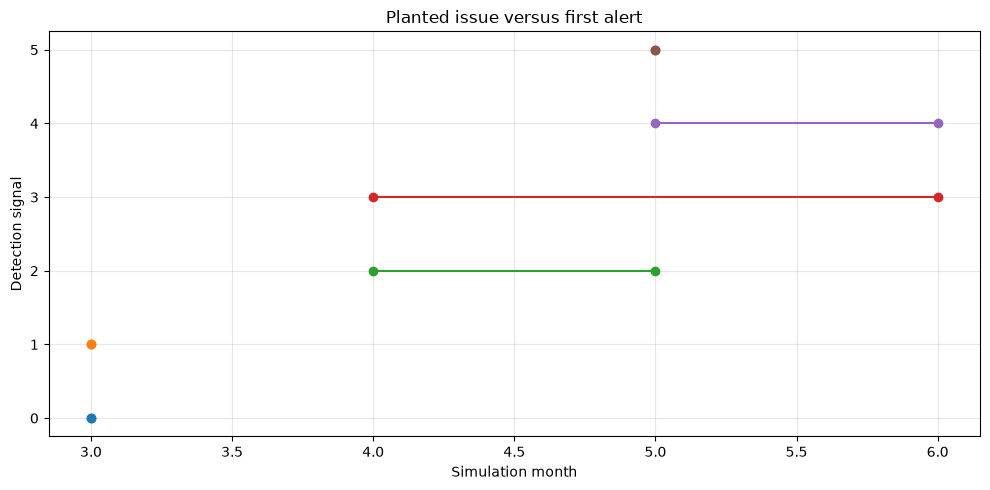

In [6]:
display(detection[
    ["signal", "planted_month", "first_alert_month",
     "delay_batches", "false_positive_months"]
])

plt.figure(figsize=(10, 5))

for _, row in detection.iterrows():
    if pd.notna(row["first_alert_month"]):
        plt.plot(
            [row["planted_month"], row["first_alert_month"]],
            [row.name, row.name],
            marker="o"
        )

plt.xlabel("Simulation month")
plt.ylabel("Detection signal")
plt.title("Planted issue versus first alert")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Findings and conclusion

In [7]:
print("BASELINE ACCURACY:", round(metrics.iloc[0]["accuracy"], 4))
print("MONTH 6 ACCURACY:", round(metrics.iloc[-1]["accuracy"], 4))
print("MONTH 6 FAIRNESS GAP:", round(metrics.iloc[-1]["fairness_gap"], 4))
print("MONTH 6 DRIFT SHARE:", round(metrics.iloc[-1]["evidently_drift_share"], 4))

print("\nKEY FINDINGS")
print("- Feature drift was detected from month 3.")
print("- Accuracy degradation was first alerted in month 5.")
print("- Fairness TPR-gap violation was first alerted in month 6.")
print("- The monitoring system uses a 50% feature-drift threshold.")
print("- Detection delays are measured in simulated monthly batches, not real elapsed time.")


BASELINE ACCURACY: 0.6967
MONTH 6 ACCURACY: 0.665
MONTH 6 FAIRNESS GAP: 0.1345
MONTH 6 DRIFT SHARE: 0.8

KEY FINDINGS
- Feature drift was detected from month 3.
- Accuracy degradation was first alerted in month 5.
- Fairness TPR-gap violation was first alerted in month 6.
- The monitoring system uses a 50% feature-drift threshold.
- Detection delays are measured in simulated monthly batches, not real elapsed time.
